In [1]:
%matplotlib inline

import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch

import cute_rmsnorm
import triton_rmsnorm
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

M, N = 4096, 4096
EPS = cute_rmsnorm.EPS  # the CUDA kernel hardcodes the same value


def rmsnorm(x, w):
    return torch.nn.functional.rms_norm(x, (x.shape[-1],), w, EPS)

In [2]:
AUTOTUNE = True  # False runs each kernel with its own defaults

TRITON_KERNEL = triton_rmsnorm.rmsnorm_kernel(autotune=AUTOTUNE)

IMPLEMENTATIONS = {
    "torch": make_runner("torch", rmsnorm),
    "torch_compile": make_runner("torch_compile", lambda x, w: x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + EPS) * w),
    "triton": make_runner(
        "triton",
        TRITON_KERNEL,
        extra_args=lambda x, w, out: (x.stride(0), x.shape[1], EPS),
        grid=lambda meta: (meta["x_ptr"].shape[0],),
    ),
    "cute": make_runner("cute", cute_rmsnorm.rmsnorm(autotune=AUTOTUNE)),
    "cute_vec": make_runner("cute", cute_rmsnorm.rmsnorm_vec(autotune=AUTOTUNE)),
    "cuda": make_runner("cuda", "cuda_rmsnorm.cu", entry="rmsnorm"),
}

In [3]:
# Tests: row lengths around block and vector boundaries. cute_vec needs N % 4 == 0.
for m, n in [(1, 1), (3, 7), (5, 255), (2, 256), (7, 1000), (4, 4096), (3, 8196), (M, N)]:
    inputs = make_inputs((m, n), (n,))
    for name, fn in IMPLEMENTATIONS.items():
        if name == "cute_vec" and n % 4:
            continue
        torch.testing.assert_close(fn(*inputs), rmsnorm(*inputs), msg=f"{name}, {m}x{n}")
print("OK")

/home/fvelikon/projects/ysda-dsl-benches/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


OK


         torch: 34.720 us (p20-p80: 33.946-35.776) | 1.932859 TFLOP/s | 3866.19 GB/s | 1.24x
 torch_compile: 43.168 us (p20-p80: 42.976-45.024) | 1.554597 TFLOP/s | 3109.57 GB/s | 1.00x
        triton: 28.672 us (p20-p80: 28.608-28.800) | 2.340571 TFLOP/s | 4681.71 GB/s | 1.51x
          cute: 36.928 us (p20-p80: 36.768-37.862) | 1.817289 TFLOP/s | 3635.02 GB/s | 1.17x
      cute_vec: 31.328 us (p20-p80: 30.586-40.102) | 2.142137 TFLOP/s | 4284.80 GB/s | 1.38x
          cuda: 51.952 us (p20-p80: 51.168-53.222) | 1.291747 TFLOP/s | 2583.81 GB/s | 0.83x


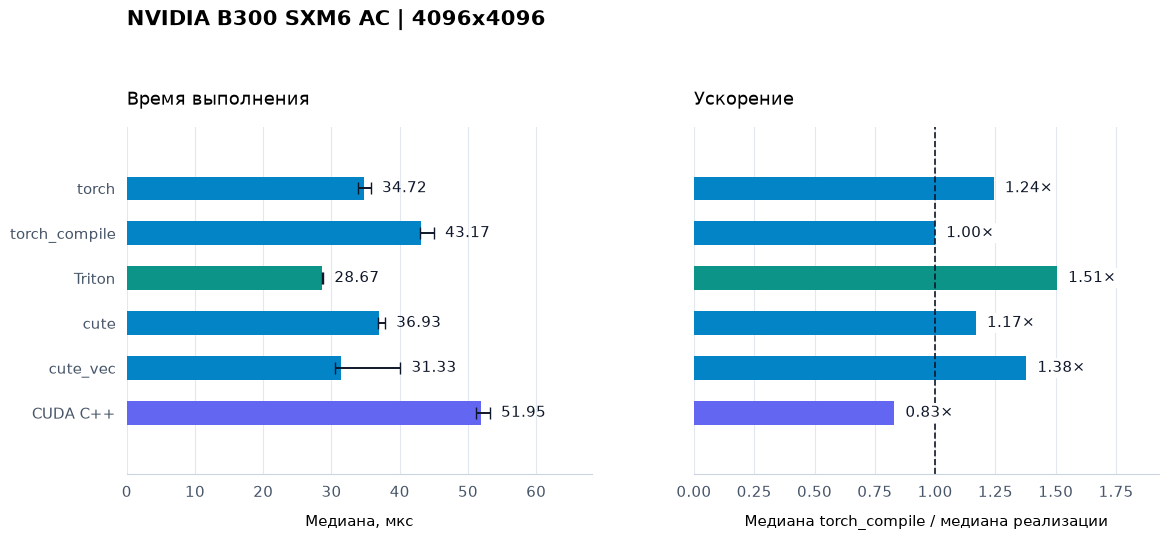

triton config: BLOCK_SIZE: 4096, num_warps: 16, num_ctas: 1, num_stages: 3, maxnreg: None


cute config: {'threads_per_block': 128}


cute_vec config: {'threads_per_block': 256}


In [4]:
inputs = make_inputs((M, N), (N,))
# square, add, multiply by 1/rms, multiply by w
results = run_benchmark(IMPLEMENTATIONS, inputs, reference=rmsnorm, flops=4 * M * N)
plot_benchmark(results, baseline="torch_compile", title=f"{torch.cuda.get_device_name()} | {M}x{N}")
plt.show()
if AUTOTUNE:
    print("triton config:", TRITON_KERNEL.best_config)
    print("cute config:", IMPLEMENTATIONS["cute"].asm()["rmsnorm"]["config"])
    print("cute_vec config:", IMPLEMENTATIONS["cute_vec"].asm()["rmsnorm_vec"]["config"])

In [5]:
for name, fn in IMPLEMENTATIONS.items():
    dump_asm(fn.asm(), Path("asm") / name)
    print(name, list(fn.asm()))

torch []


torch_compile ['triton_poi_fused_add_mean_mul_pow_rsqrt_0', 'triton_red_fused_add_mean_mul_pow_rsqrt_0']


triton ['rmsnorm_kernel']


cute ['rmsnorm']


cute_vec ['rmsnorm_vec']


cuda ['cuda_rmsnorm']
